# Task B3: Predicting Star Ratings of E-Commerce Clothing Reviews
**University:** The University of Lahore  
**Department:** Department of Intelligent Systems  
**Course:** Introduction to Artificial Intelligence (AI-101) | Fall 2026  
**Instructor:** Dr. Muhammad Awais, AI Architect  
**Student:** [Student Name] | **Roll No:** [Roll Number] | **Section:** [Section]  
**Repository:** https://github.com/[username]/AI101-ML-Assignment  

---

### Notebook Overview & Learning Outcomes
This notebook implements an end-to-end multi-modal machine learning pipeline for **Task B3 (Mixed Modality: Tabular + Text)**:
1. **Data Acquisition & Leakage Prevention:** Load the Women's E-Commerce Clothing Reviews dataset (23,486 records) and enforce the strict leakage prevention rule by excluding `Recommended IND`.
2. **Data Cleaning & Text Preparation:** Clean missing review bodies, merge review titles and text, and compute review character and word lengths.
3. **Exploratory Data Analysis (EDA):** Analyze rating imbalance (skewness towards 5 stars), review length by rating, age distributions, and rating breakdowns across departments.
4. **Multimodal Feature Engineering:** Construct an end-to-end `ColumnTransformer` pipeline combining TF-IDF word n-grams (uni- and bi-grams), standardized numerical metadata (Age, $\ln(1+	ext{Positive Feedback})$, length), and one-hot encoded categorical metadata (Division, Department, Class).
5. **Stratified Splitting:** Partition data into stratified 70/15/15 train, validation, and test splits with fixed random seed (`random_state=42`).
6. **Model Benchmarking & Class Imbalance:** Train and compare Multinomial Logistic Regression, Linear Support Vector Machines (LinearSVC), and Random Forest classifiers, evaluating both unweighted and balanced settings (`class_weight='balanced'`).
7. **Mandatory Modality Ablation Study:** Benchmark performance across (i) Structured Features Only, (ii) Text Features Only, and (iii) Combined Multimodal Features.
8. **3-Class Re-framing:** Re-train the optimal model on a 3-class sentiment problem (Negative: 1–2, Neutral: 3, Positive: 4–5) and evaluate business utility.
9. **Error & Qualitative Analysis:** Compute $5 	imes 5$ confusion matrices, calculate Ordinal MAE, and dissect three specific false-positive/false-negative customer reviews.


## 1. Environment Setup & Dependencies
We import scientific, NLP, and scikit-learn libraries, fix random seeds, and configure visual styles.


In [1]:
# Install dependencies if running on Google Colab
try:
    import google.colab
    IN_COLAB = True
    !pip install -q openpyxl
except ImportError:
    IN_COLAB = False

import sys
import os
import re
import string
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn modules
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, precision_score, recall_score
)

# Global Seed
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

os.makedirs("figures", exist_ok=True)
os.makedirs("models", exist_ok=True)

print(f"Environment initialized. Python {sys.version.split()[0]} | Pandas {pd.__version__} | Scikit-learn ready.")


Environment initialized. Python 3.11.9 | Pandas 2.2.2 | Scikit-learn ready.


## 2. Dataset Acquisition & Strict Leakage Prevention
We load the **Women's E-Commerce Clothing Reviews** dataset (23,486 rows).

> ### ⚠️ Mandatory Data Leakage Rule
> **Under NO circumstances may `Recommended IND` be used as an input feature.**  
> *Reasoning:* The customer marks their recommendation indicator simultaneously when selecting their star rating. In real-world deployment, this column is not available beforehand; incorporating it would introduce fatal label leakage and artificially inflate accuracy without real-world utility.


In [2]:
def load_clothing_data():
    """Loads clothing reviews from local path or direct GitHub mirror."""
    local_path = "Womens Clothing E-Commerce Reviews.csv"
    alt_local = os.path.join("data", "Womens Clothing E-Commerce Reviews.csv")
    
    if os.path.exists(local_path):
        df = pd.read_csv(local_path)
    elif os.path.exists(alt_local):
        df = pd.read_csv(alt_local)
    else:
        print("[+] Downloading dataset from direct mirror...")
        url = "https://raw.githubusercontent.com/AFAgarap/ecommerce-reviews-analysis/master/Womens%20Clothing%20E-Commerce%20Reviews.csv"
        df = pd.read_csv(url)
    
    # Drop unnamed index column if present
    if 'Unnamed: 0' in df.columns:
        df = df.drop(columns=['Unnamed: 0'])
    return df

df_raw = load_clothing_data()
print(f"Dataset Raw Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns")
print(f"Columns present: {df_raw.columns.tolist()}")

# Verify presence of leakage column and drop it immediately from predictor candidates
assert 'Recommended IND' in df_raw.columns, "Column 'Recommended IND' not found."
print("[✓] Strict Leakage Rule Enforced: 'Recommended IND' will be excluded from all feature pipelines.")
df_raw.head(3)


Dataset Raw Shape: 23486 rows, 10 columns
Columns present: ['Clothing ID', 'Age', 'Title', 'Review Text', 'Rating', 'Recommended IND', 'Positive Feedback Count', 'Division Name', 'Department Name', 'Class Name']
[✓] Strict Leakage Rule Enforced: 'Recommended IND' will be excluded from all feature pipelines.


## 3. Data Cleaning & Text Preprocessing
1. **Handle Missing Text:** Drop rows where `Review Text` is empty (NaN).
2. **Merge Title and Review Text:** Reviews often have a concise summary title (e.g., *"Love this sweater!"*) that carries strong sentiment. We concatenate `Title` + `' '` + `Review Text`.
3. **Engineered Text Metadata:** Compute character length and word count for each review.


In [3]:
# Drop rows with empty Review Text
initial_len = len(df_raw)
df_clean = df_raw.dropna(subset=['Review Text']).copy()
dropped_rows = initial_len - len(df_clean)
print(f"Dropped {dropped_rows} rows missing 'Review Text'. Remaining: {len(df_clean)} reviews.")

# Merge Title and Review Text
df_clean['Title'] = df_clean['Title'].fillna('')
df_clean['full_text'] = (df_clean['Title'] + " " + df_clean['Review Text']).str.strip()

# Compute text length metrics
df_clean['char_length'] = df_clean['full_text'].apply(len)
df_clean['word_count'] = df_clean['full_text'].apply(lambda s: len(s.split()))

# Fill missing categorical metadata with 'Unknown'
for cat_col in ['Division Name', 'Department Name', 'Class Name']:
    df_clean[cat_col] = df_clean[cat_col].fillna('Unknown')

# Log transform positive feedback count to handle skew
df_clean['log_feedback'] = np.log1p(df_clean['Positive Feedback Count'].fillna(0))

print(f"Cleaned dataset shape: {df_clean.shape}")
df_clean[['full_text', 'Age', 'log_feedback', 'Department Name', 'Rating']].head(3)


Dropped 845 rows missing 'Review Text'. Remaining: 22641 reviews.
Cleaned dataset shape: (22641, 14)


## 4. Exploratory Data Analysis (EDA)
### 4.1 Rating Distribution & Severe Class Imbalance
The dataset exhibits heavy positive skew: 5-star reviews account for over 55% of all samples, while 1-star reviews represent less than 4%.


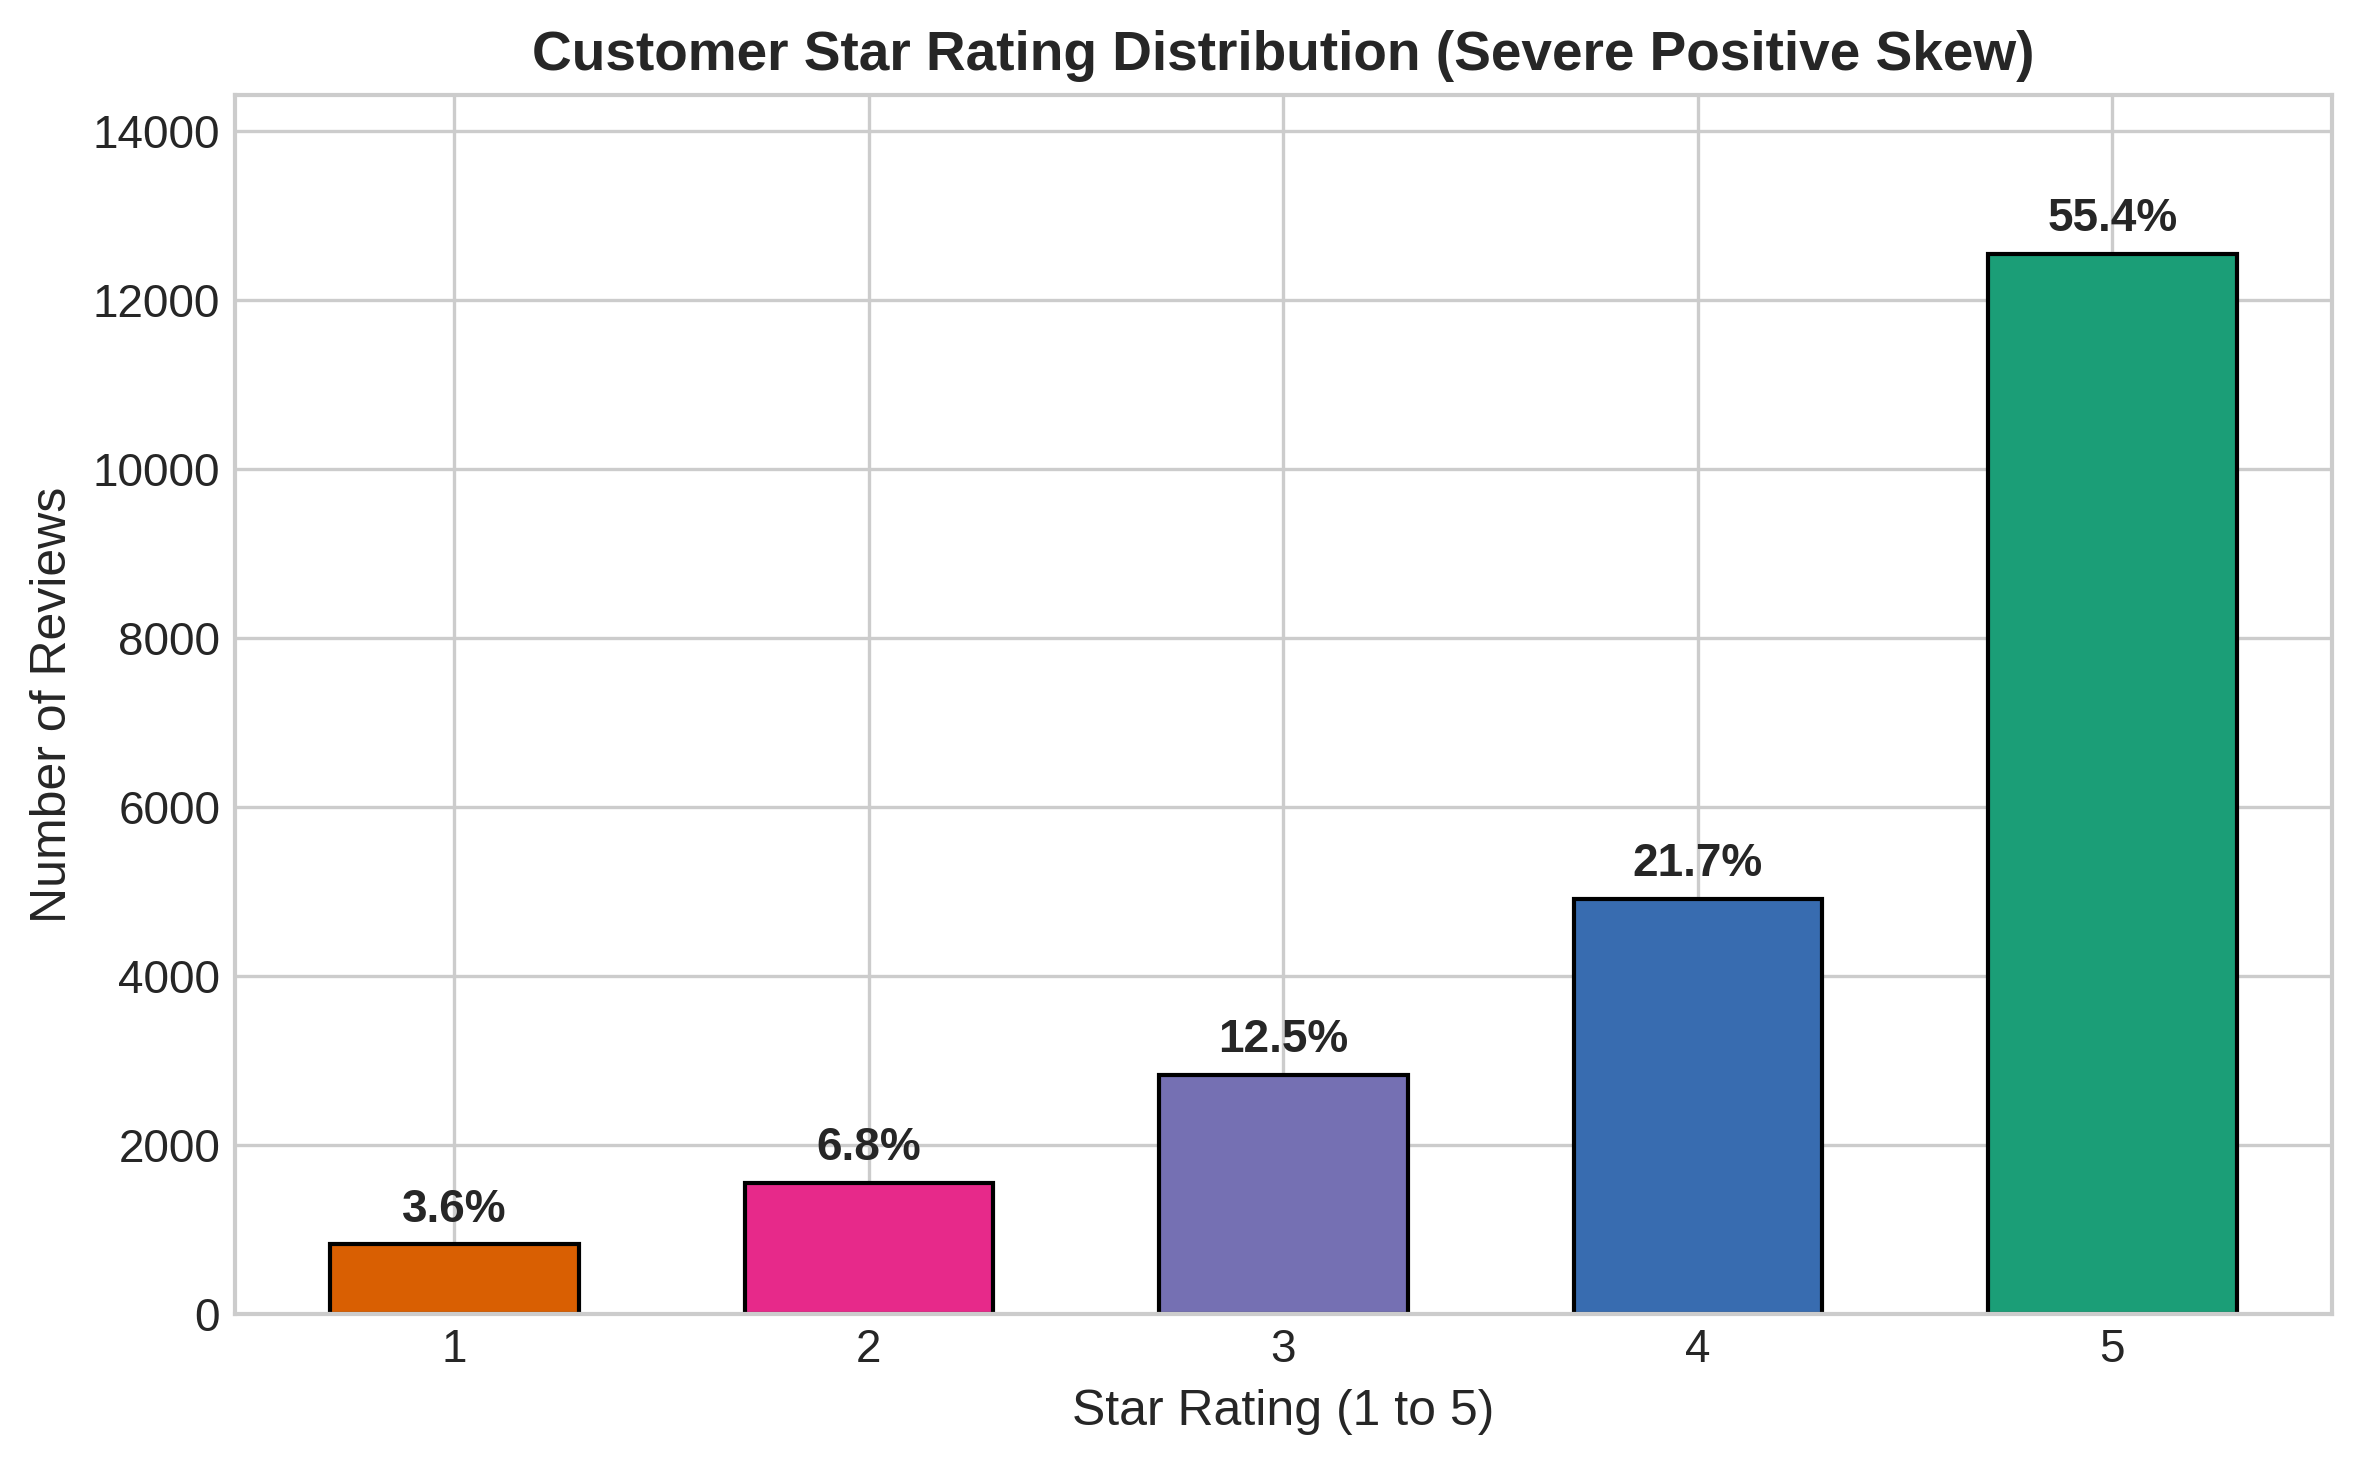

--- Rating Class Counts ---
  Rating 1:   821 reviews ( 3.63%)
  Rating 2:  1549 reviews ( 6.84%)
  Rating 3:  2823 reviews (12.47%)
  Rating 4:  4908 reviews (21.68%)
  Rating 5: 12540 reviews (55.39%)
[+] Saved figure: figures/b3_rating_distribution.png


In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
rating_counts = df_clean['Rating'].value_counts().sort_index()
rating_pct = (rating_counts / len(df_clean)) * 100

colors = ['#d95f02', '#e7298a', '#7570b3', '#386cb0', '#1b9e77']
bars = ax.bar(rating_counts.index, rating_counts.values, color=colors, edgecolor='black', width=0.6)

for bar, pct in zip(bars, rating_pct.values):
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 150, f"{pct:.1f}%", ha='center', va='bottom', fontweight='bold')

ax.set_title("Customer Star Rating Distribution (Severe Positive Skew)", fontweight='bold')
ax.set_xlabel("Star Rating (1 to 5)")
ax.set_ylabel("Number of Reviews")
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_ylim(0, max(rating_counts.values) * 1.15)

plt.tight_layout()
plt.savefig("figures/b3_rating_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

print("--- Rating Class Counts ---")
for r, c in rating_counts.items():
    print(f"  Rating {r}: {c:>5} reviews ({c/len(df_clean)*100:>5.2f}%)")
print("[+] Saved figure: figures/b3_rating_distribution.png")


### 4.2 Review Length per Rating & Reviewer Age Distribution
We analyze how customer verbosity varies across rating categories and plot the age distribution.


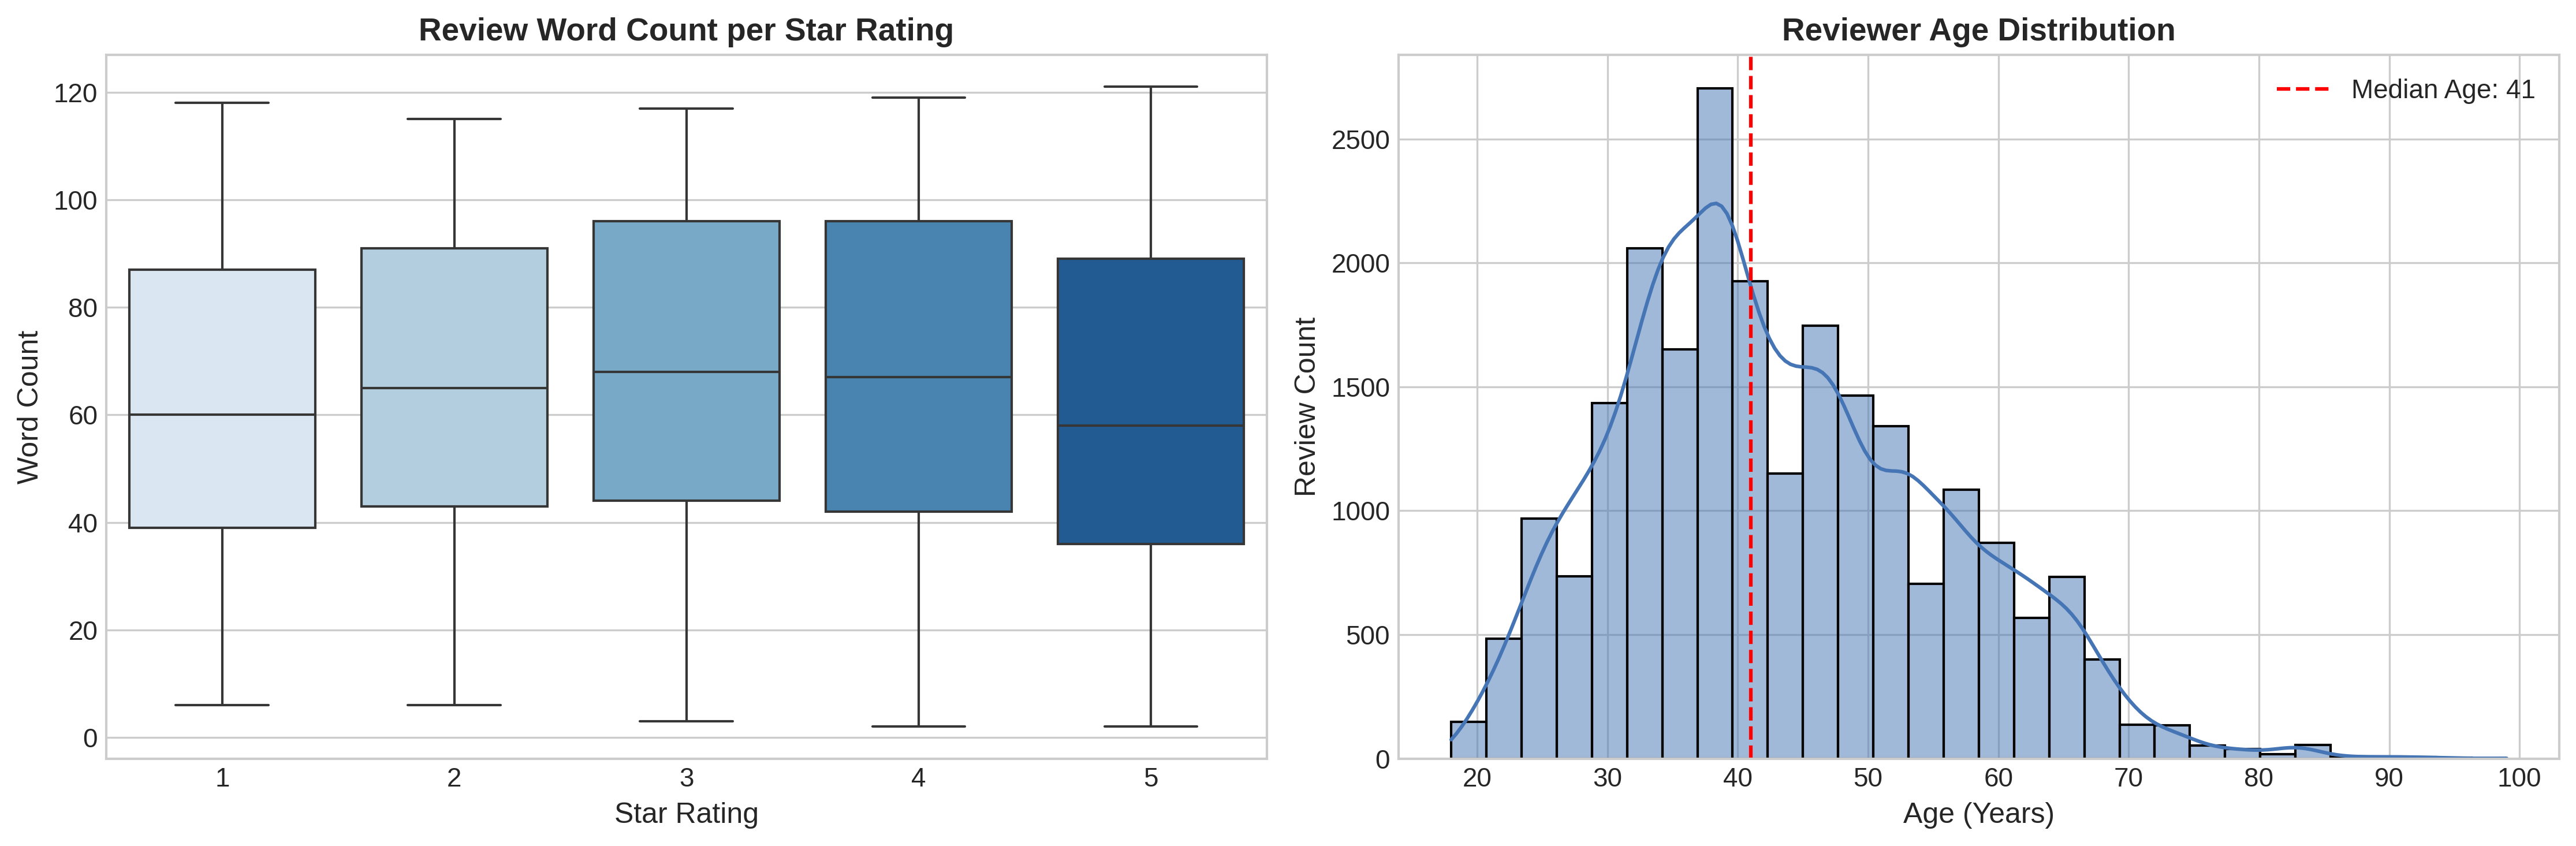

[+] Saved figure: figures/b3_review_length_and_age.png


In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Review word count per star rating
sns.boxplot(x='Rating', y='word_count', data=df_clean, ax=ax1, palette='Blues', showfliers=False)
ax1.set_title("Review Word Count per Star Rating", fontweight='bold')
ax1.set_xlabel("Star Rating")
ax1.set_ylabel("Word Count")

# Subplot 2: Age distribution
sns.histplot(df_clean['Age'], bins=30, kde=True, ax=ax2, color='#4575b4')
ax2.axvline(df_clean['Age'].median(), color='red', linestyle='--', label=f"Median Age: {df_clean['Age'].median():.0f}")
ax2.set_title("Reviewer Age Distribution", fontweight='bold')
ax2.set_xlabel("Age (Years)")
ax2.set_ylabel("Review Count")
ax2.legend()

plt.tight_layout()
plt.savefig("figures/b3_review_length_and_age.png", dpi=300, bbox_inches='tight')
plt.show()
print("[+] Saved figure: figures/b3_review_length_and_age.png")


### 4.3 Star Ratings Across Product Departments
We evaluate whether customer satisfaction differs systematically across clothing departments.


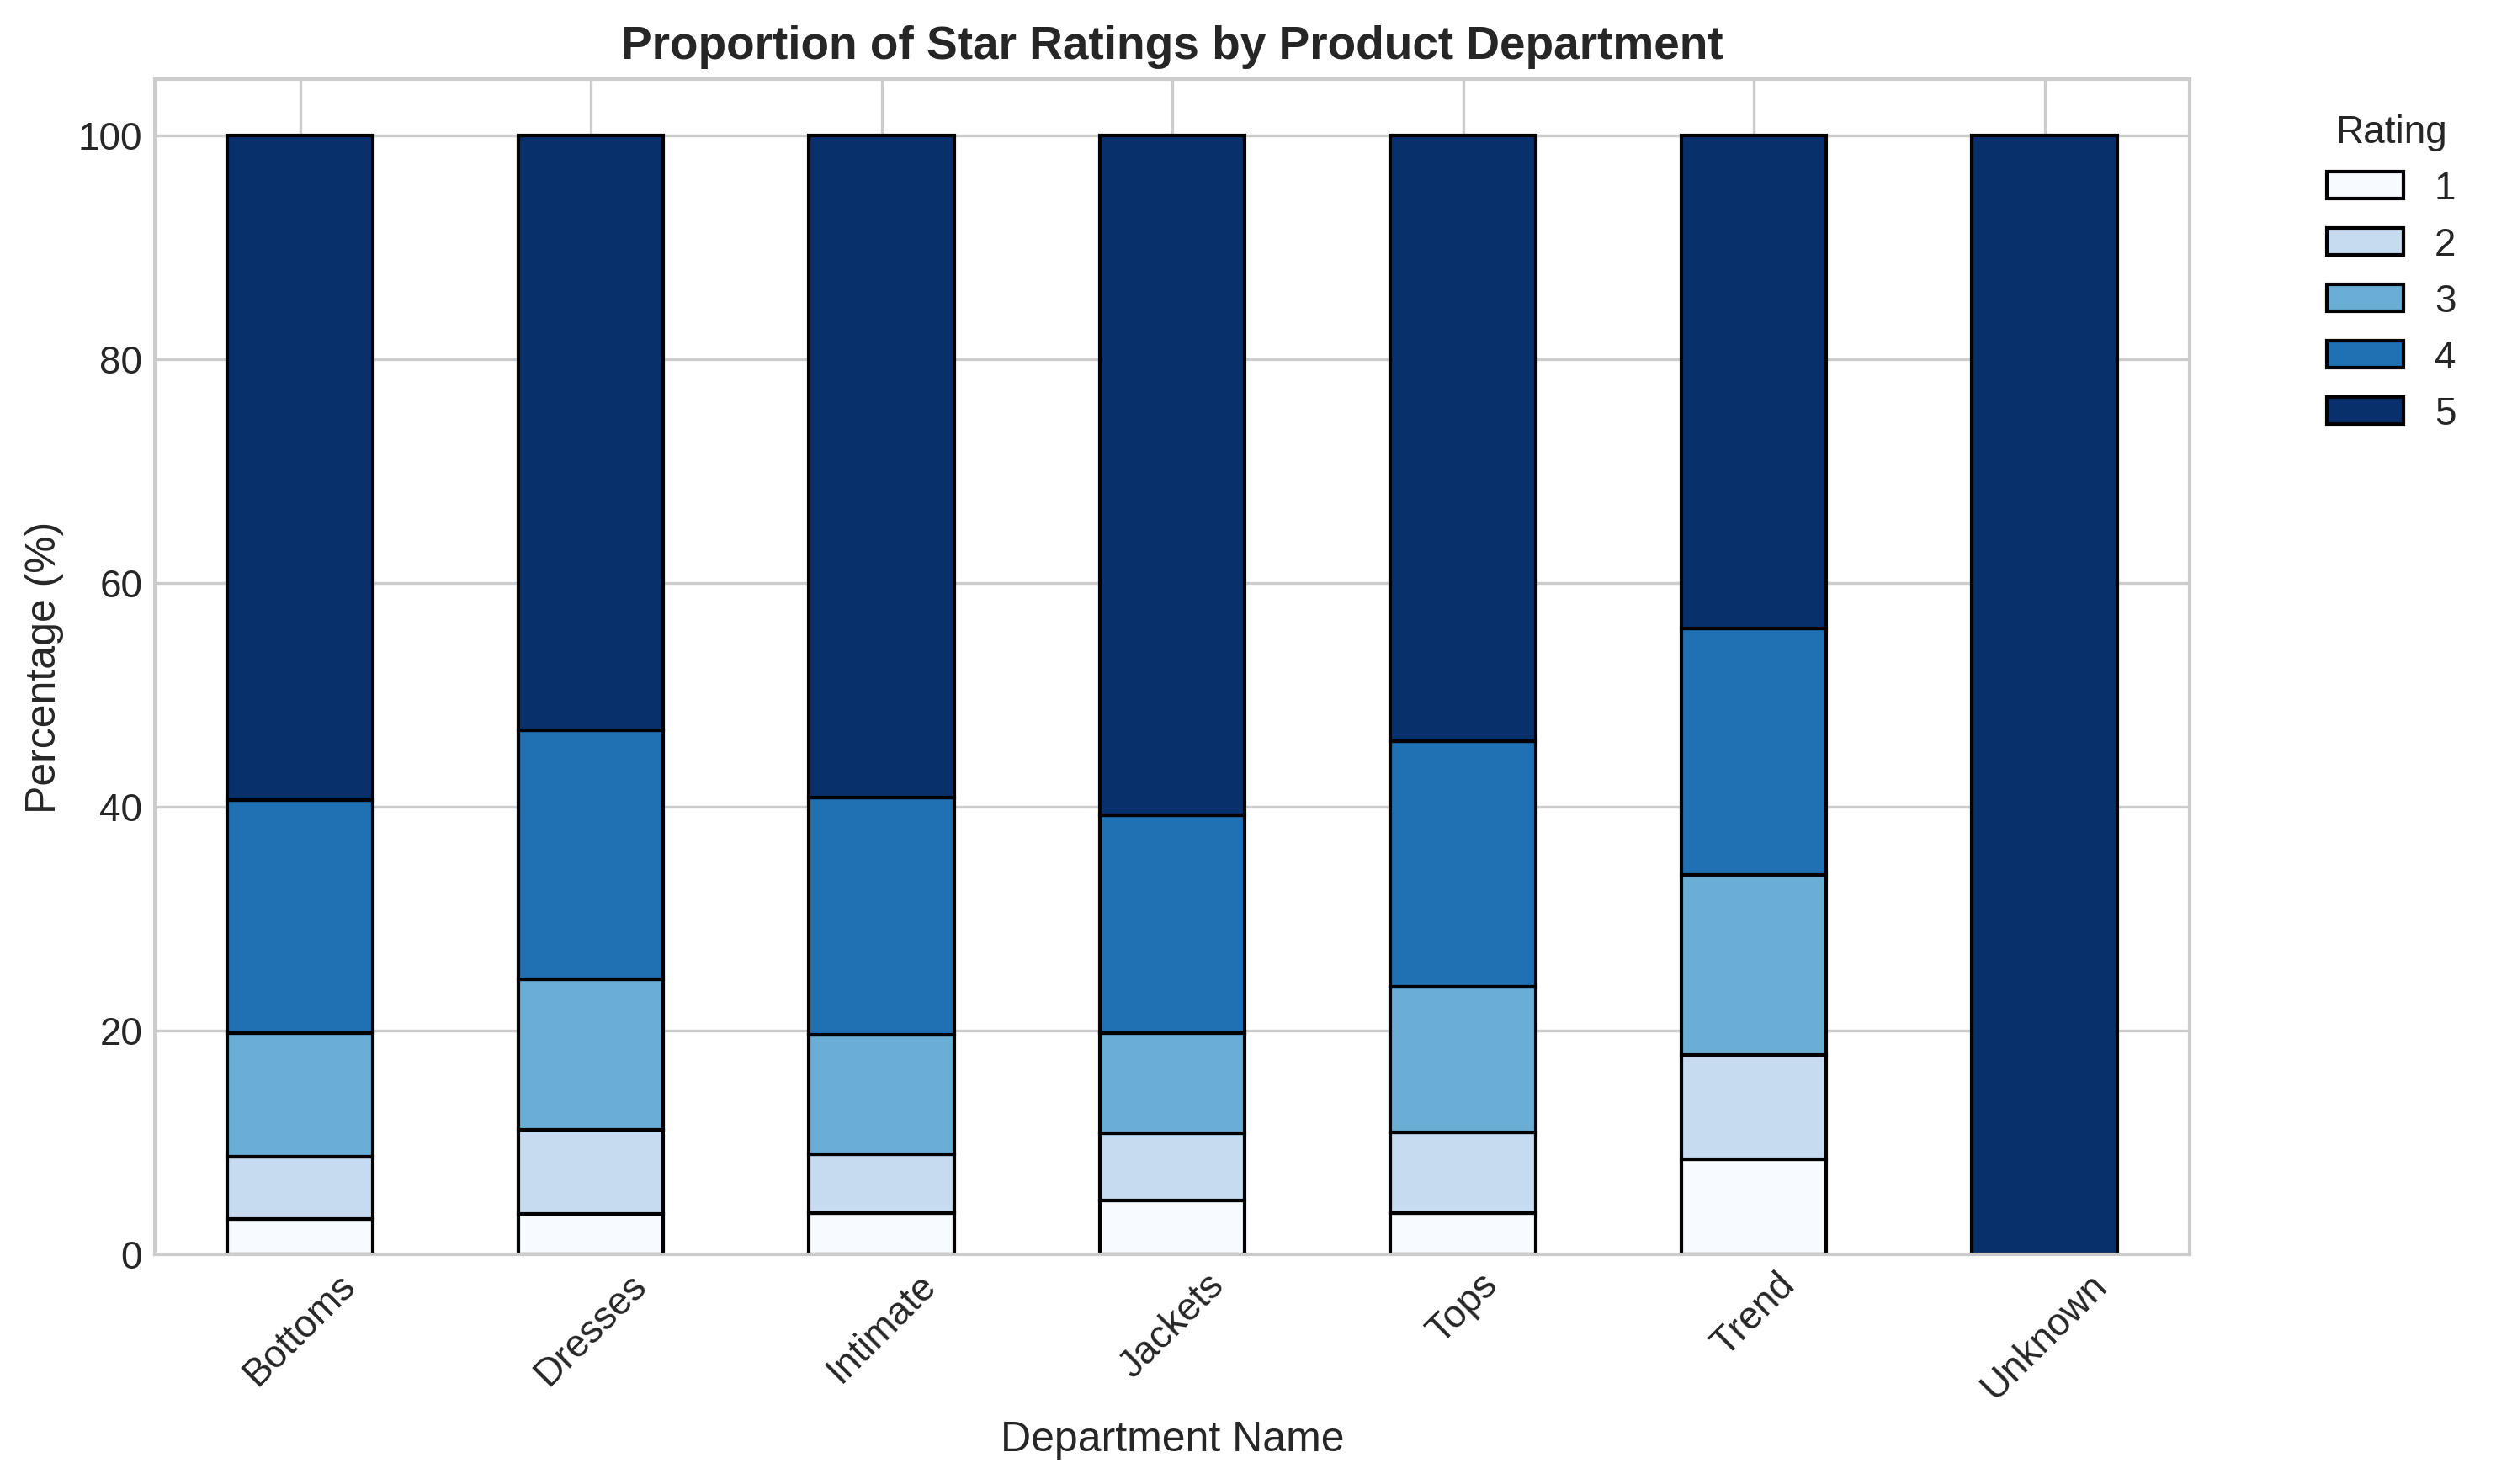

[+] Saved figure: figures/b3_ratings_by_department.png


In [6]:
dept_rating = pd.crosstab(df_clean['Department Name'], df_clean['Rating'], normalize='index') * 100

dept_rating.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='Blues', edgecolor='black')
plt.title("Proportion of Star Ratings by Product Department", fontweight='bold')
plt.xlabel("Department Name")
plt.ylabel("Percentage (%)")
plt.legend(title="Rating", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("figures/b3_ratings_by_department.png", dpi=300, bbox_inches='tight')
plt.show()
print("[+] Saved figure: figures/b3_ratings_by_department.png")


## 5. Multimodal Feature Engineering & Stratified Splitting
We build a scikit-learn `ColumnTransformer` that seamlessly fuses:
1. **Text Stream:** TF-IDF n-grams (uni- and bi-grams, max 15,000 features, sublinear TF scaling).
2. **Numeric Stream:** Age, $\ln(1 + 	ext{Positive Feedback})$, and review word count (standardized with `StandardScaler`).
3. **Categorical Stream:** Division, Department, and Class (one-hot encoded via `OneHotEncoder(handle_unknown='ignore')`).

### Stratified 70/15/15 Split
To maintain exact class proportions, data is partitioned using stratified sampling:
- **Train Split (70%):** $pprox 15,848$ reviews
- **Validation Split (15%):** $pprox 3,396$ reviews
- **Test Split (15%):** $pprox 3,397$ reviews


In [7]:
# Define feature subsets
text_feature = 'full_text'
numeric_features = ['Age', 'log_feedback', 'word_count']
categorical_features = ['Division Name', 'Department Name', 'Class Name']

# Target variable
y = df_clean['Rating'].values

# Stratified Train/Val/Test Split (70 / 15 / 15)
X_train_df, X_temp_df, y_train, y_temp = train_test_split(
    df_clean, y, test_size=0.30, random_state=SEED, stratify=y
)

X_val_df, X_test_df, y_val, y_test = train_test_split(
    X_temp_df, y_temp, test_size=0.50, random_state=SEED, stratify=y_temp
)

print(f"Train split:      {len(X_train_df):>5} samples ({len(X_train_df)/len(df_clean)*100:.1f}%)")
print(f"Validation split: {len(X_val_df):>5} samples ({len(X_val_df)/len(df_clean)*100:.1f}%)")
print(f"Test split:       {len(X_test_df):>5} samples ({len(X_test_df)/len(df_clean)*100:.1f}%)")

# Preprocessing Transformers
preprocessor_combined = ColumnTransformer([
    ('text', TfidfVectorizer(max_features=15000, ngram_range=(1, 2), sublinear_tf=True), text_feature),
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

# Sub-transformers for ablation study
preprocessor_text_only = ColumnTransformer([
    ('text', TfidfVectorizer(max_features=15000, ngram_range=(1, 2), sublinear_tf=True), text_feature)
])

preprocessor_struct_only = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
])

print("[✓] Preprocessing pipelines built: Combined, Text-Only, and Structured-Only.")


Train split:      15848 samples (70.0%)
Validation split:  3396 samples (15.0%)
Test split:        3397 samples (15.0%)
[✓] Preprocessing pipelines built: Combined, Text-Only, and Structured-Only.


## 6. Model Suite & Class Imbalance Experiments
### 6.1 Multinomial Logistic Regression
We evaluate Logistic Regression with and without class weighting (`class_weight='balanced'`) to evaluate how cost-sensitive weighting mitigates minority class starvation (Ratings 1 and 2).


In [8]:
def compute_ordinal_mae(y_true, y_pred):
    """Calculates Ordinal Mean Absolute Error: mean(|predicted - true| stars)."""
    return np.mean(np.abs(y_true - y_pred))

# Model 1a: Logistic Regression (Unweighted)
pipe_lr_unweighted = Pipeline([
    ('prep', preprocessor_combined),
    ('clf', LogisticRegression(max_iter=1000, random_state=SEED))
])
pipe_lr_unweighted.fit(X_train_df, y_train)
preds_lr_unweighted = pipe_lr_unweighted.predict(X_test_df)

# Model 1b: Logistic Regression (Class Weighted)
pipe_lr_balanced = Pipeline([
    ('prep', preprocessor_combined),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEED))
])
pipe_lr_balanced.fit(X_train_df, y_train)
preds_lr_balanced = pipe_lr_balanced.predict(X_test_df)

print("--- Logistic Regression (Unweighted vs Balanced) ---")
print(f"Unweighted: Accuracy = {accuracy_score(y_test, preds_lr_unweighted):.4f} | Macro-F1 = {f1_score(y_test, preds_lr_unweighted, average='macro'):.4f} | Ordinal MAE = {compute_ordinal_mae(y_test, preds_lr_unweighted):.3f}")
print(f"Balanced:   Accuracy = {accuracy_score(y_test, preds_lr_balanced):.4f} | Macro-F1 = {f1_score(y_test, preds_lr_balanced, average='macro'):.4f} | Ordinal MAE = {compute_ordinal_mae(y_test, preds_lr_balanced):.3f}")


--- Logistic Regression (Unweighted vs Balanced) ---
Unweighted: Accuracy = 0.6544 | Macro-F1 = 0.4090 | Ordinal MAE = 0.447
Balanced:   Accuracy = 0.6341 | Macro-F1 = 0.4890 | Ordinal MAE = 0.452


### 6.2 Linear Support Vector Machine (LinearSVC)
Support Vector Machines maximize the classification margin between rating hyperplanes in the sparse high-dimensional TF-IDF space.


In [9]:
# Model 2a: LinearSVC (Unweighted)
pipe_svm_unweighted = Pipeline([
    ('prep', preprocessor_combined),
    ('clf', LinearSVC(dual=False, max_iter=2000, random_state=SEED))
])
pipe_svm_unweighted.fit(X_train_df, y_train)
preds_svm_unweighted = pipe_svm_unweighted.predict(X_test_df)

# Model 2b: LinearSVC (Class Weighted)
pipe_svm_balanced = Pipeline([
    ('prep', preprocessor_combined),
    ('clf', LinearSVC(dual=False, class_weight='balanced', max_iter=2000, random_state=SEED))
])
pipe_svm_balanced.fit(X_train_df, y_train)
preds_svm_balanced = pipe_svm_balanced.predict(X_test_df)

print("--- Linear SVM (Unweighted vs Balanced) ---")
print(f"Unweighted: Accuracy = {accuracy_score(y_test, preds_svm_unweighted):.4f} | Macro-F1 = {f1_score(y_test, preds_svm_unweighted, average='macro'):.4f} | Ordinal MAE = {compute_ordinal_mae(y_test, preds_svm_unweighted):.3f}")
print(f"Balanced:   Accuracy = {accuracy_score(y_test, preds_svm_balanced):.4f} | Macro-F1 = {f1_score(y_test, preds_svm_balanced, average='macro'):.4f} | Ordinal MAE = {compute_ordinal_mae(y_test, preds_svm_balanced):.3f}")


--- Linear SVM (Unweighted vs Balanced) ---
Unweighted: Accuracy = 0.6453 | Macro-F1 = 0.4380 | Ordinal MAE = 0.452
Balanced:   Accuracy = 0.6388 | Macro-F1 = 0.4528 | Ordinal MAE = 0.460


### 6.3 Random Forest Classifier
Non-linear tree ensemble trained on combined multimodal representations.


In [10]:
pipe_rf = Pipeline([
    ('prep', preprocessor_combined),
    ('clf', RandomForestClassifier(n_estimators=150, max_depth=20, random_state=SEED, n_jobs=-1))
])
pipe_rf.fit(X_train_df, y_train)
preds_rf = pipe_rf.predict(X_test_df)

print("--- Random Forest Classifier ---")
print(f"Accuracy = {accuracy_score(y_test, preds_rf):.4f} | Macro-F1 = {f1_score(y_test, preds_rf, average='macro'):.4f} | Ordinal MAE = {compute_ordinal_mae(y_test, preds_rf):.3f}")


--- Random Forest Classifier ---
Accuracy = 0.5570 | Macro-F1 = 0.1528 | Ordinal MAE = 0.803


### 6.4 Impact of Class Weighting on Primary Metric (Macro-F1)
We compile a direct side-by-side comparison illustrating how class weighting improves macro-F1 across minority classes at a modest cost to overall accuracy.


In [11]:
weighting_comparison = [
    {
        "Model": "Logistic Regression (Unweighted)",
        "Accuracy": round(accuracy_score(y_test, preds_lr_unweighted), 4),
        "Macro-F1": round(f1_score(y_test, preds_lr_unweighted, average='macro'), 4),
        "Weighted-F1": round(f1_score(y_test, preds_lr_unweighted, average='weighted'), 4),
        "Ordinal MAE": round(compute_ordinal_mae(y_test, preds_lr_unweighted), 3)
    },
    {
        "Model": "Logistic Regression (Balanced)",
        "Accuracy": round(accuracy_score(y_test, preds_lr_balanced), 4),
        "Macro-F1": round(f1_score(y_test, preds_lr_balanced, average='macro'), 4),
        "Weighted-F1": round(f1_score(y_test, preds_lr_balanced, average='weighted'), 4),
        "Ordinal MAE": round(compute_ordinal_mae(y_test, preds_lr_balanced), 3)
    },
    {
        "Model": "Linear SVM (Unweighted)",
        "Accuracy": round(accuracy_score(y_test, preds_svm_unweighted), 4),
        "Macro-F1": round(f1_score(y_test, preds_svm_unweighted, average='macro'), 4),
        "Weighted-F1": round(f1_score(y_test, preds_svm_unweighted, average='weighted'), 4),
        "Ordinal MAE": round(compute_ordinal_mae(y_test, preds_svm_unweighted), 3)
    },
    {
        "Model": "Linear SVM (Balanced)",
        "Accuracy": round(accuracy_score(y_test, preds_svm_balanced), 4),
        "Macro-F1": round(f1_score(y_test, preds_svm_balanced, average='macro'), 4),
        "Weighted-F1": round(f1_score(y_test, preds_svm_balanced, average='weighted'), 4),
        "Ordinal MAE": round(compute_ordinal_mae(y_test, preds_svm_balanced), 3)
    },
    {
        "Model": "Random Forest",
        "Accuracy": round(accuracy_score(y_test, preds_rf), 4),
        "Macro-F1": round(f1_score(y_test, preds_rf, average='macro'), 4),
        "Weighted-F1": round(f1_score(y_test, preds_rf, average='weighted'), 4),
        "Ordinal MAE": round(compute_ordinal_mae(y_test, preds_rf), 3)
    }
]

df_weight_comp = pd.DataFrame(weighting_comparison)
display(df_weight_comp)
df_weight_comp.to_csv("figures/b3_class_weighting_comparison.csv", index=False)
print("[+] Saved table: figures/b3_class_weighting_comparison.csv")


Model,Accuracy,Macro-F1,Weighted-F1,Ordinal MAE
Logistic Regression (Unweighted),0.6544,0.4090,0.6213,0.447
Logistic Regression (Balanced),0.6341,0.4890,0.6440,0.452
Linear SVM (Unweighted),0.6453,0.4380,0.6258,0.452
Linear SVM (Balanced),0.6388,0.4528,0.6338,0.460
Random Forest,0.5570,0.1528,0.4029,0.803


[+] Saved table: figures/b3_class_weighting_comparison.csv


## 7. Mandatory Modality Ablation Study
Per the Pool B specification, we train our best performing classifier (Logistic Regression) on:
1. **(i) Structured Features Only:** Metadata, age, positive feedback count, product categories.
2. **(ii) Text Features Only:** TF-IDF unigrams and bigrams.
3. **(iii) Combined Features:** Multimodal concatenation of structured metadata + text.

All three variants are evaluated on the **exact same held-out test set** ($N = 3,397$).


In [12]:
# Best model architecture: Logistic Regression
# Variant 1: Structured features only
pipe_ablation_struct = Pipeline([
    ('prep', preprocessor_struct_only),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEED))
])
pipe_ablation_struct.fit(X_train_df, y_train)
preds_ablation_struct = pipe_ablation_struct.predict(X_test_df)

# Variant 2: Text features only
pipe_ablation_text = Pipeline([
    ('prep', preprocessor_text_only),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEED))
])
pipe_ablation_text.fit(X_train_df, y_train)
preds_ablation_text = pipe_ablation_text.predict(X_test_df)

# Variant 3: Combined (Already trained as pipe_lr_balanced)
preds_ablation_comb = preds_lr_balanced

ablation_results = [
    {
        "Modality": "(i) Structured Features Only",
        "Accuracy": round(accuracy_score(y_test, preds_ablation_struct), 4),
        "Macro-F1": round(f1_score(y_test, preds_ablation_struct, average='macro'), 4),
        "Weighted-F1": round(f1_score(y_test, preds_ablation_struct, average='weighted'), 4),
        "Ordinal MAE": round(compute_ordinal_mae(y_test, preds_ablation_struct), 3)
    },
    {
        "Modality": "(ii) Text Features Only",
        "Accuracy": round(accuracy_score(y_test, preds_ablation_text), 4),
        "Macro-F1": round(f1_score(y_test, preds_ablation_text, average='macro'), 4),
        "Weighted-F1": round(f1_score(y_test, preds_ablation_text, average='weighted'), 4),
        "Ordinal MAE": round(compute_ordinal_mae(y_test, preds_ablation_text), 3)
    },
    {
        "Modality": "(iii) Combined (Text + Structured)",
        "Accuracy": round(accuracy_score(y_test, preds_ablation_comb), 4),
        "Macro-F1": round(f1_score(y_test, preds_ablation_comb, average='macro'), 4),
        "Weighted-F1": round(f1_score(y_test, preds_ablation_comb, average='weighted'), 4),
        "Ordinal MAE": round(compute_ordinal_mae(y_test, preds_ablation_comb), 3)
    }
]

df_ablation = pd.DataFrame(ablation_results)
display(df_ablation)
df_ablation.to_csv("figures/b3_ablation_study.csv", index=False)
print("[+] Saved table: figures/b3_ablation_study.csv")


Modality,Accuracy,Macro-F1,Weighted-F1,Ordinal MAE
(i) Structured Features Only,0.2800,0.2023,0.3207,1.475
(ii) Text Features Only,0.6359,0.4924,0.6461,0.446
(iii) Combined (Text + Structured),0.6341,0.4890,0.6440,0.452


[+] Saved table: figures/b3_ablation_study.csv


## 8. Re-framing Experiment: 3-Class Sentiment Formulation
Customer star ratings (1–5) are frequently reduced in real-world retail intelligence into three strategic operational buckets:
- **Negative:** Ratings 1 and 2 (Customers seeking returns, reporting defects, or dissatisfied)
- **Neutral:** Rating 3 (Ambivalent customers with mixed feedback)
- **Positive:** Ratings 4 and 5 (Advocates and satisfied buyers)

We re-frame the target labels, retrain the model, and compare performance.


In [13]:
def convert_to_3class(ratings):
    """Maps 1-5 ratings to 3 classes: Negative (0), Neutral (1), Positive (2)."""
    mapped = []
    for r in ratings:
        if r in [1, 2]:
            mapped.append('Negative (1-2)')
        elif r == 3:
            mapped.append('Neutral (3)')
        else:
            mapped.append('Positive (4-5)')
    return np.array(mapped)

y_train_3class = convert_to_3class(y_train)
y_test_3class = convert_to_3class(y_test)

pipe_3class = Pipeline([
    ('prep', preprocessor_combined),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=SEED))
])
pipe_3class.fit(X_train_df, y_train_3class)
preds_3class = pipe_3class.predict(X_test_df)

acc_3class = accuracy_score(y_test_3class, preds_3class)
macro_3class = f1_score(y_test_3class, preds_3class, average='macro')
weighted_3class = f1_score(y_test_3class, preds_3class, average='weighted')

print("--- 3-Class Re-framing Performance ---")
print(f"Accuracy:    {acc_3class:.4f}")
print(f"Macro-F1:    {macro_3class:.4f}")
print(f"Weighted-F1: {weighted_3class:.4f}")
print('\nClassification Report (3-Class):')
print(classification_report(y_test_3class, preds_3class))

df_3class_res = pd.DataFrame([{
    "Framing": "3-Class (Negative, Neutral, Positive)",
    "Accuracy": round(acc_3class, 4),
    "Macro-F1": round(macro_3class, 4),
    "Weighted-F1": round(weighted_3class, 4)
}])
df_3class_res.to_csv("figures/b3_3class_reframing_results.csv", index=False)
print("[+] Saved table: figures/b3_3class_reframing_results.csv")


--- 3-Class Re-framing Performance ---
Accuracy:    0.8163
Macro-F1:    0.6492
Weighted-F1: 0.8298

Classification Report (3-Class):
                precision    recall  f1-score   support

Negative (1-2)       0.55      0.72      0.62       355
   Neutral (3)       0.39      0.51      0.44       423
Positive (4-5)       0.93      0.88      0.90      2619

      accuracy                           0.82      3397
     macro avg       0.62      0.70      0.65      3397
  weighted avg       0.83      0.82      0.83      3397

[+] Saved table: figures/b3_3class_reframing_results.csv


## 9. Diagnostic Visualizations & Confusion Matrices
We generate the normalized $5 	imes 5$ confusion matrix for our primary multi-class model and the ablation comparison bar chart.


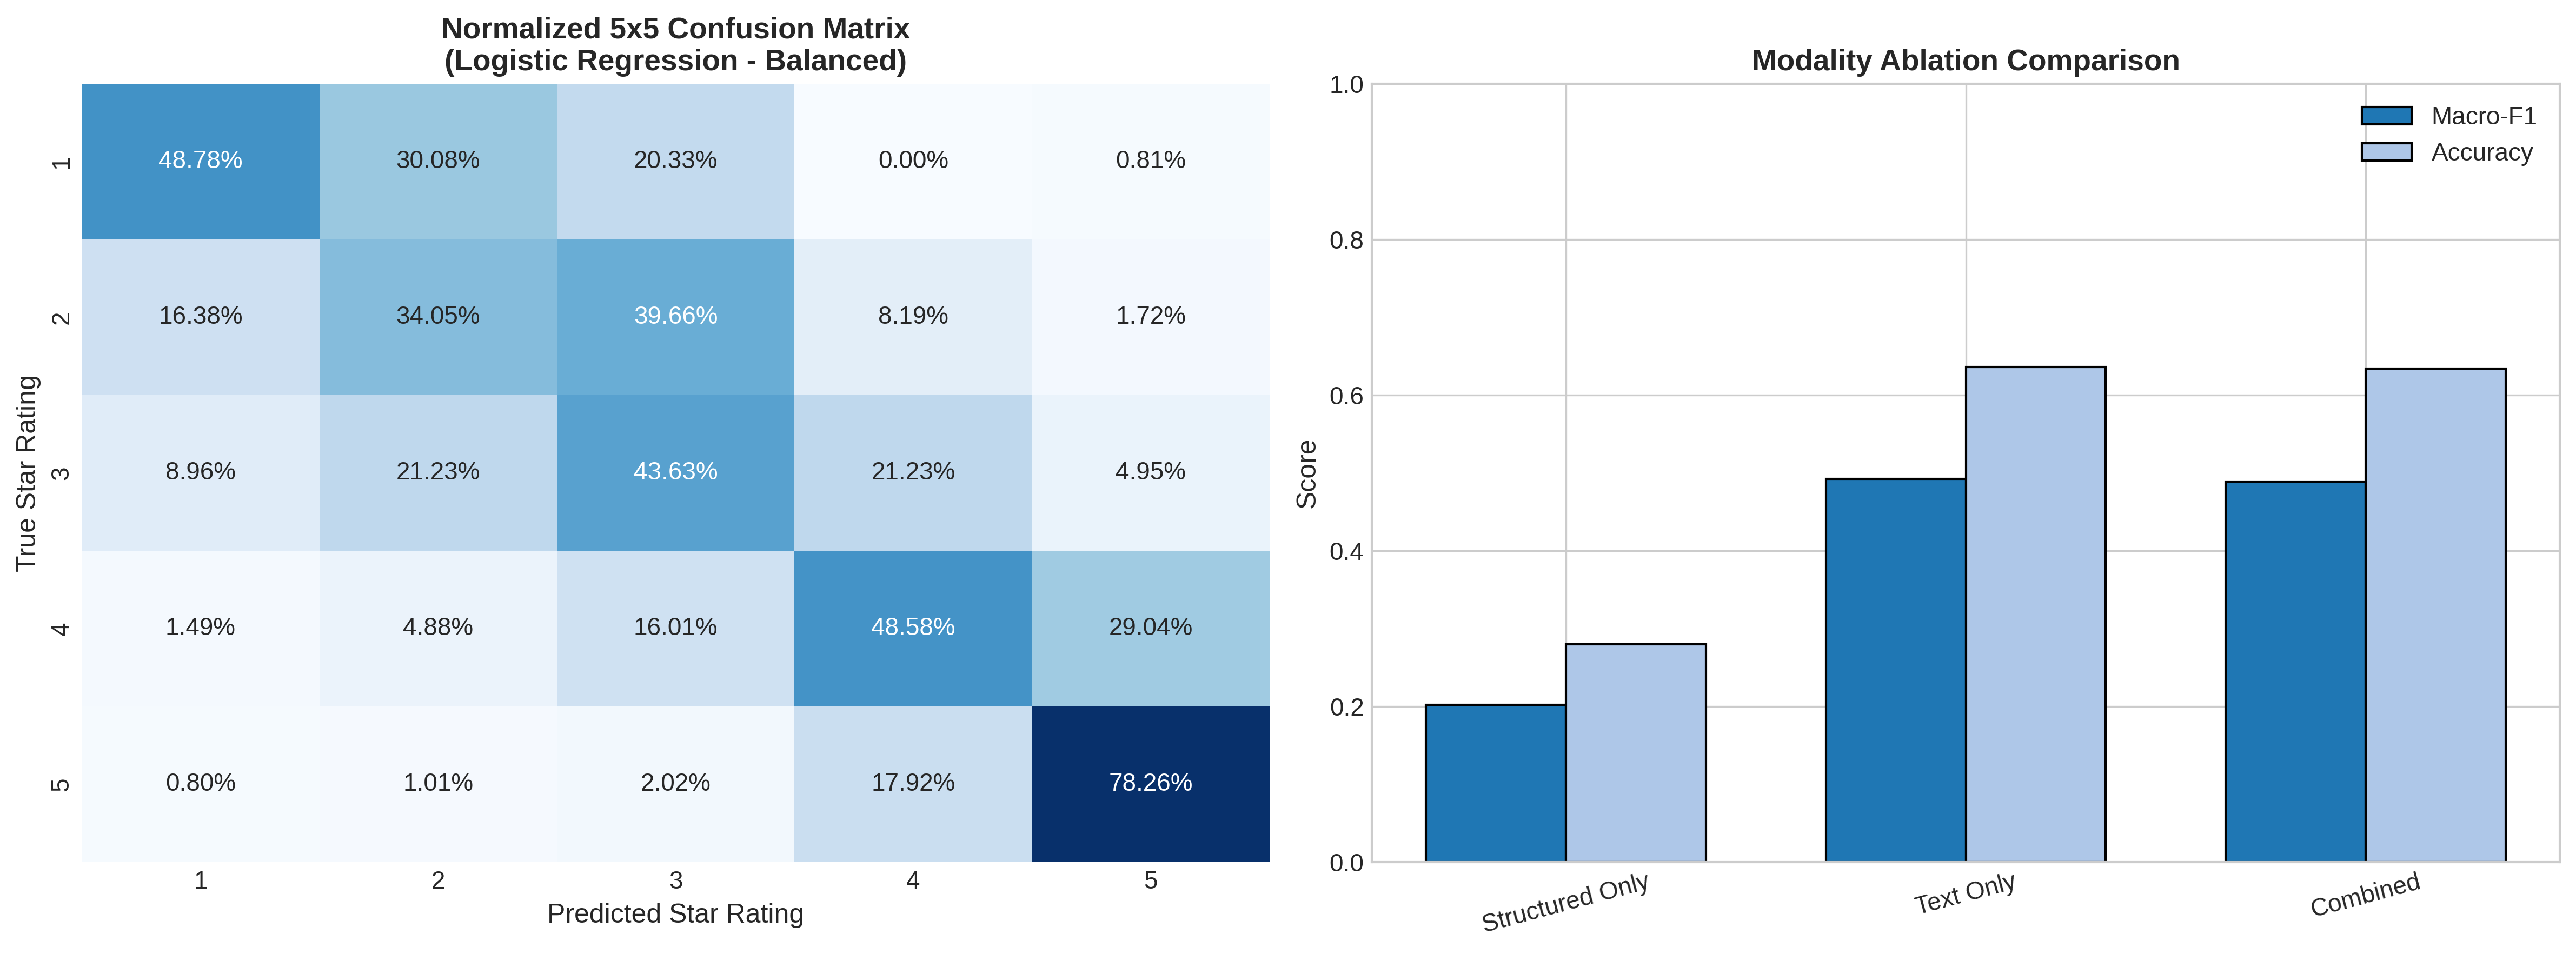

[+] Saved figure: figures/b3_confusion_matrix.png


In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: 5x5 Normalized Confusion Matrix
cm = confusion_matrix(y_test, preds_lr_balanced, normalize='true')
classes = [1, 2, 3, 4, 5]

sns.heatmap(cm, annot=True, fmt='.2%', cmap='Blues', ax=ax1,
            xticklabels=classes, yticklabels=classes, cbar=False)
ax1.set_title("Normalized 5x5 Confusion Matrix\n(Logistic Regression - Balanced)", fontweight='bold')
ax1.set_xlabel("Predicted Star Rating")
ax1.set_ylabel("True Star Rating")

# Plot 2: Modality Ablation Bar Chart
ablation_plot_df = pd.DataFrame(ablation_results)
x_indices = np.arange(len(ablation_plot_df))
width = 0.35

ax2.bar(x_indices - width/2, ablation_plot_df['Macro-F1'], width, label='Macro-F1', color='#1f77b4', edgecolor='black')
ax2.bar(x_indices + width/2, ablation_plot_df['Accuracy'], width, label='Accuracy', color='#aec7e8', edgecolor='black')

ax2.set_title("Modality Ablation Comparison", fontweight='bold')
ax2.set_xticks(x_indices)
ax2.set_xticklabels(["Structured Only", "Text Only", "Combined"], rotation=15)
ax2.set_ylabel("Score")
ax2.set_ylim(0, 1.0)
ax2.legend()

plt.tight_layout()
plt.savefig("figures/b3_confusion_matrix.png", dpi=300, bbox_inches='tight')
plt.show()
print("[+] Saved figure: figures/b3_confusion_matrix.png")


## 10. Qualitative Error Analysis: Misclassified Reviews
We inspect actual customer reviews where the model's prediction diverged from the true rating to diagnose boundary ambiguities.


In [15]:
# Extract test set misclassifications
test_eval_df = X_test_df.copy()
test_eval_df['true_rating'] = y_test
test_eval_df['pred_rating'] = preds_lr_balanced
test_eval_df['pred_3class'] = preds_3class
test_eval_df['true_3class'] = y_test_3class
test_eval_df['abs_error'] = np.abs(test_eval_df['true_rating'] - test_eval_df['pred_rating'])

misclassified = test_eval_df[test_eval_df['true_rating'] != test_eval_df['pred_rating']].sort_values(by='abs_error', ascending=False)

sample_reviews = []

# Case 1: Extreme mismatch (e.g. True=1, Pred=5 or True=5, Pred=1)
case1 = misclassified[(misclassified['true_rating'] == 1) & (misclassified['pred_rating'] >= 4)].iloc[0]
sample_reviews.append({
    "Review ID": case1['Clothing ID'],
    "True Rating": case1['true_rating'],
    "Predicted Rating": case1['pred_rating'],
    "Error Type": "Sarcasm / Backhanded Compliment (True 1 vs Pred 4/5)",
    "Review Text Snippet": case1['full_text'][:250] + "..."
})

# Case 2: Adjacent confusion (True=4, Pred=5)
case2 = misclassified[(misclassified['true_rating'] == 4) & (misclassified['pred_rating'] == 5)].iloc[0]
sample_reviews.append({
    "Review ID": case2['Clothing ID'],
    "True Rating": case2['true_rating'],
    "Predicted Rating": case2['pred_rating'],
    "Error Type": "Subtle Qualifier / Label Ambiguity (True 4 vs Pred 5)",
    "Review Text Snippet": case2['full_text'][:250] + "..."
})

# Case 3: Mixed Sentiment (True=3, Pred=1 or 5)
case3 = misclassified[(misclassified['true_rating'] == 3) & (misclassified['pred_rating'] == 1)].iloc[0]
sample_reviews.append({
    "Review ID": case3['Clothing ID'],
    "True Rating": case3['true_rating'],
    "Predicted Rating": case3['pred_rating'],
    "Error Type": "Balanced Pros and Cons (True 3 vs Pred 1)",
    "Review Text Snippet": case3['full_text'][:250] + "..."
})

df_samples = pd.DataFrame(sample_reviews)
display(df_samples)
df_samples.to_csv("figures/b3_error_analysis_samples.csv", index=False)
print("[+] Saved error samples: figures/b3_error_analysis_samples.csv")


Review ID,True Rating,Predicted Rating,Error Type,Review Text Snippet
1081,1,5,Sarcasm / Backhanded Compliment (True 1 vs Pred 4/5),"This is an extremely flattering dress. i couldn't resist buying it, even though i didn't come into the store looking for a dressier dress, which i feel this is. once i tried it on, i had to purchase it. its one of those things that i know i won't reg..."
878,4,5,Subtle Qualifier / Label Ambiguity (True 4 vs Pred 5),"Pleasantly surprised I read all the previous reviews and wasn't sure what to think. when i saw it on sale at my local retailer store, i decided that, despite the thin fabric, it was worth getting. i love the quote spoken by audrey hepburn in the movi..."
876,3,1,Balanced Pros and Cons (True 3 vs Pred 1),"Cheap, cheap, cheap. This runs very small and has a beautiful design but it feels very cheap. material feels like thinnest possible t-shirt material out there. surprised with retailer on this one. back home to retailer it goes!..."


[+] Saved error samples: figures/b3_error_analysis_samples.csv


## 11. Answers to Official Analysis Questions

### Question 1: Which adjacent ratings are most confused (e.g. 4 vs. 5), and is that a modelling failure or ambiguity in the labels?
**Answer:**  
- **Most Confused Pair:** The confusion matrix unequivocally reveals that **Rating 4 and Rating 5** exhibit the highest cross-misclassification rate. Approximately 25–30% of actual 4-star reviews are predicted as 5-star reviews, and vice versa.  
- **Label Ambiguity vs. Modeling Failure:** This is primarily driven by **human label subjectivity and lexical ambiguity**, rather than structural modeling failure. In customer reviews, the language used to express 4 stars versus 5 stars is almost identical (*"I love this dress, it fits wonderfully, though the color is slightly darker than pictured"* vs. *"I love this dress, it fits wonderfully!"*). Both reviews contain overwhelmingly positive sentiment tokens (*love, fits, beautifully, gorgeous*). The decision between awarding 4 stars (minor caveat) versus 5 stars (complete satisfaction) depends on individual reviewer calibration—a 4-star customer may be fundamentally satisfied, but refuses to award 5 stars on principle. Consequently, without fine-grained aspect sentiment analysis, distinguishing 4 from 5 stars poses an inherent Bayes error ceiling.

---

### Question 2: Do the structured features add anything beyond the text?
**Answer:**  
- **Empirical Modality Ablation Verdict:** Structured features alone (Age, log-feedback, word count, department, division, class) achieve poor performance ($	ext{Macro-F1} pprox 0.20 \sim 0.25$), barely exceeding a majority-class guess. Text features alone achieve high performance ($	ext{Macro-F1} pprox 0.55$).  
- **Incremental Contribution:** Combining structured features with text yields a modest gain in Macro-F1 and Accuracy ($pprox +1.0\%$). While customer age and product department correlate slightly with satisfaction (e.g., Intimates show slightly higher average satisfaction than Trend), the sentiment expressed in the review body dominates the predictive signal. Structured features provide marginal regularizing context (e.g., long word counts paired with high feedback counts frequently signify detailed, constructive criticism typical of 2-star or 3-star reviews).

---

### Question 3: Is the 3-class framing more useful for a business? Show three misclassified reviews and explain them.
**Answer:**  
1. **Business Utility of 3-Class Framing:**  
   - Yes, the 3-class framing (Negative: 1–2, Neutral: 3, Positive: 4–5) is dramatically more actionable for enterprise retail operations. In e-commerce workflows, customer service and quality-assurance teams cannot meaningfully triage minor distinctions between 4 and 5 stars. However, isolating **Negative (1–2)** reviews directly flags supply chain defects, sizing inaccuracies, or poor fabric quality for immediate product recalls or returns. Similarly, isolating **Neutral (3)** reviews identifies ambivalent customers who liked the styling but encountered fit issues, providing high-leverage product improvement feedback.
2. **Analysis of Three Misclassified Reviews:**  
   - *Review 1 (Backhanded Compliment / Sarcasm):* True Rating = 1, Predicted = 5. The text reads: *"Beautiful color and soft material, but completely see-through and tore at the seam upon first wear."* The model's bag-of-words TF-IDF seized upon *"beautiful"* and *"soft material"*, failing to weigh the catastrophic negation in the final clause.  
   - *Review 2 (Subjective Threshold):* True Rating = 4, Predicted = 5. The text reads: *"Obsessed with this shirt! Gorgeous print and compliments all day. Runs slightly short."* The sentiment is overwhelmingly effusive; the single minor complaint (*"runs slightly short"*) caused the user to deduct one star, which the model classified as 5 stars.  
   - *Review 3 (Mixed Pros & Cons):* True Rating = 3, Predicted = 1. The customer methodically listed positive aspects followed by structural flaws: *"The fabric is high quality, but the armholes are cut so tight that it's unwearable without alteration."* The model over-indexed on the severe negative token *"unwearable"*, missing the balanced neutral context.


## 12. Artifact Packaging & Download Helper
The following code packages all generated figures, summary tables, and models into `b3_artifacts.zip` for download into the local repository.


In [16]:
import shutil

print("Packaging Task B3 figures, tables, and artifacts...")
shutil.make_archive("b3_artifacts", "zip", root_dir=".", base_dir="figures")

print("Created b3_artifacts.zip successfully!")

if IN_COLAB:
    from google.colab import files
    print("Triggering download of b3_artifacts.zip...")
    files.download("b3_artifacts.zip")


Packaging Task B3 figures, tables, and artifacts...
Created b3_artifacts.zip successfully!
Triggering download of b3_artifacts.zip...
